In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

df = pd.read_csv("UCI_Credit_Card.csv")
print("Full data shape:", df.shape)

df = df.sample(n=30000, random_state=42).reset_index(drop=True)
print("Sample shape   :", df.shape)
df.head()

Full data shape: (30000, 25)
Sample shape   : (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,2309,30000.0,1,2,2,25,0,0,0,0,0,0,8864.0,10062.0,11581.0,12580.0,13716.0,14828.0,1500.0,2000.0,1500.0,1500.0,1500.0,2000.0,0
1,22405,150000.0,2,1,2,26,0,0,0,0,0,0,136736.0,125651.0,116684.0,101581.0,77741.0,77264.0,4486.0,4235.0,3161.0,2647.0,2669.0,2669.0,0
2,23398,70000.0,2,3,1,32,0,0,0,0,0,0,70122.0,69080.0,68530.0,69753.0,70111.0,70212.0,2431.0,3112.0,3000.0,2438.0,2500.0,2554.0,0
3,25059,130000.0,1,3,2,49,0,0,0,0,0,-1,20678.0,18956.0,16172.0,16898.0,11236.0,6944.0,1610.0,1808.0,7014.0,27.0,7011.0,4408.0,0
4,2665,50000.0,2,2,2,36,0,0,0,0,0,2,94228.0,47635.0,42361.0,19574.0,20295.0,19439.0,2000.0,1500.0,1000.0,1800.0,0.0,1000.0,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   300

In [5]:
df.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,-0.266200,-0.291100,51223.330900,49179.075167,4.701315e+04,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,1.133187,1.149988,73635.860576,71173.768783,6.934939e+04,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-165580.000000,-69777.000000,-1.572640e+05,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,3558.750000,2984.750000,2.666250e+03,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,22381.500000,21200.000000,2.008850e+04,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,67091.000000,64006.250000,6.016475e+04,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,964511.000000,983931.000000,1.664089e+06,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [6]:
df.nunique().sort_values()

default.payment.next.month        2
SEX                               2
MARRIAGE                          4
EDUCATION                         7
PAY_5                            10
PAY_6                            10
PAY_0                            11
PAY_2                            11
PAY_3                            11
PAY_4                            11
AGE                              56
LIMIT_BAL                        81
PAY_AMT5                       6897
PAY_AMT4                       6937
PAY_AMT6                       6939
PAY_AMT3                       7518
PAY_AMT2                       7899
PAY_AMT1                       7943
BILL_AMT6                     20604
BILL_AMT5                     21010
BILL_AMT4                     21548
BILL_AMT3                     22026
BILL_AMT2                     22346
BILL_AMT1                     22723
ID                            30000
dtype: int64

In [7]:
df = df.rename(columns={"PAY_0": "PAY_1", "default.payment.next.month": "DEFAULT"})
print(df.columns.tolist())

print("Nulls     :", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'DEFAULT']
Nulls     : 0
Duplicates: 0


In [8]:
df = df.drop(columns=["ID"])
print(df.shape)   #ID is different for every client, so the model can't learn anything from it.

(30000, 24)


In [9]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(df[col].value_counts().sort_index(), "\n")
    #Look at the output: EDUCATION also has 0, 5, and 6, and MARRIAGE has 0. The data description does not define those codes.

SEX
1    11888
2    18112
Name: count, dtype: int64 

EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64 

MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64 



In [10]:
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

print(df["EDUCATION"].value_counts().sort_index())
print(df["MARRIAGE"].value_counts().sort_index())

EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


In [ ]:
print(df["PAY_1"].value_counts().sort_index())
#-2 = no credit use that month
#-1 = paid in full on time
#0 = used revolving credit (paid the minimum)

PAY_1
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64


In [12]:
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
print((df[bill_cols] < 0).sum())

print(df["DEFAULT"].value_counts(normalize=True).round(3))

BILL_AMT1    590
BILL_AMT2    669
BILL_AMT3    655
BILL_AMT4    675
BILL_AMT5    655
BILL_AMT6    688
dtype: int64
DEFAULT
0    0.779
1    0.221
Name: proportion, dtype: float64


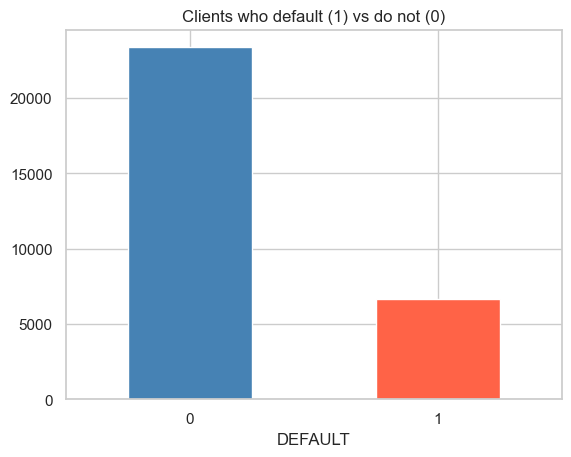

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

df["DEFAULT"].value_counts().plot(kind="bar", color=["steelblue", "tomato"])
plt.title("Clients who default (1) vs do not (0)")
plt.xticks(rotation=0)
plt.show()  # the graph show that the dataset says 79% client not default but the 21% client is default

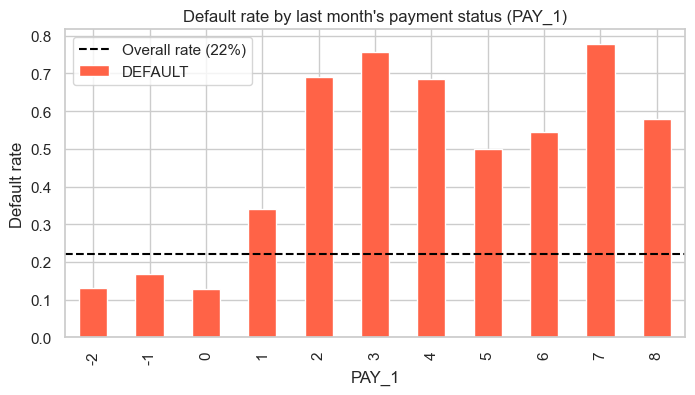

In [14]:
overall = df["DEFAULT"].mean()

df.groupby("PAY_1")["DEFAULT"].mean().plot(kind="bar", figsize=(8, 4), color="tomato")
plt.axhline(overall, color="black", linestyle="--", label=f"Overall rate ({overall:.0%})")
plt.title("Default rate by last month's payment status (PAY_1)")
plt.ylabel("Default rate")
plt.legend()
plt.show()

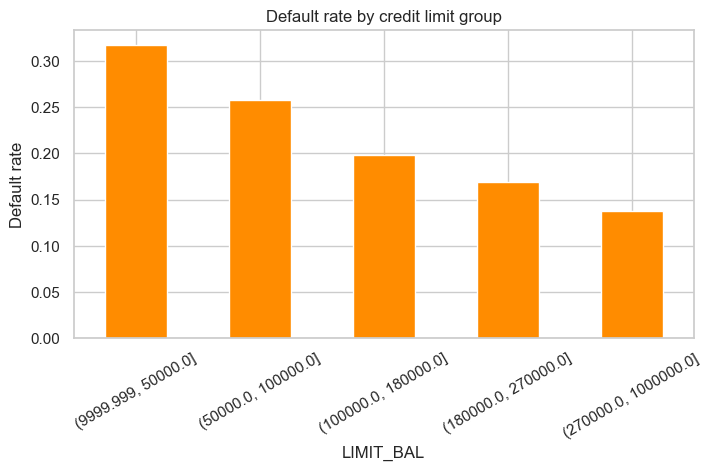

In [15]:
limit_group = pd.qcut(df["LIMIT_BAL"], 5)
df.groupby(limit_group)["DEFAULT"].mean().plot(kind="bar", figsize=(8, 4), color="darkorange")
plt.title("Default rate by credit limit group")
plt.ylabel("Default rate")
plt.xticks(rotation=30)
plt.show()

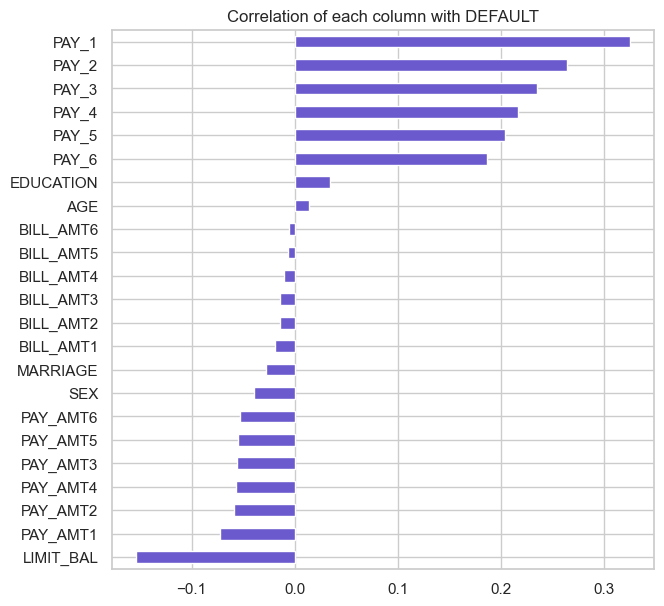

In [16]:
corr = df.corr()["DEFAULT"].drop("DEFAULT").sort_values()
corr.plot(kind="barh", figsize=(7, 7), color="slateblue")
plt.title("Correlation of each column with DEFAULT")
plt.show()

In [17]:
pay_cols = [f"PAY_{i}" for i in range(1, 7)]

df["AVG_DELAY"] = df[pay_cols].mean(axis=1)
df["MAX_DELAY"] = df[pay_cols].max(axis=1)
df["MONTHS_LATE"] = (df[pay_cols] > 0).sum(axis=1)

In [18]:
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
pay_amt_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

df["AVG_BILL"] = df[bill_cols].mean(axis=1)
df["TOTAL_PAID"] = df[pay_amt_cols].sum(axis=1)

total_bills = df[bill_cols].clip(lower=0).sum(axis=1).replace(0, np.nan)
df["PAY_RATIO"] = (df["TOTAL_PAID"] / total_bills).fillna(1).clip(0, 1)

df["UTILIZATION"] = (df["BILL_AMT1"] / df["LIMIT_BAL"]).clip(-1, 2)
df["BILL_TREND"] = df["BILL_AMT1"] - df["BILL_AMT6"]

In [19]:
new_cols = ["AVG_DELAY", "MAX_DELAY", "MONTHS_LATE", "AVG_BILL",
            "TOTAL_PAID", "PAY_RATIO", "UTILIZATION", "BILL_TREND"]
print(df[new_cols + ["DEFAULT"]].corr()["DEFAULT"].drop("DEFAULT").round(3))
print(df.shape)

AVG_DELAY      0.282
MAX_DELAY      0.331
MONTHS_LATE    0.398
AVG_BILL      -0.013
TOTAL_PAID    -0.102
PAY_RATIO     -0.091
UTILIZATION    0.088
BILL_TREND    -0.026
Name: DEFAULT, dtype: float64
(30000, 32)


In [20]:
X = df.drop(columns=["DEFAULT"])
y = df["DEFAULT"]
print(X.shape, y.shape)

(30000, 31) (30000,)


In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (24000, 31)
Test : (6000, 31)


In [22]:
print("Default rate in train:", round(y_train.mean(), 3))
print("Default rate in test :", round(y_test.mean(), 3))

Default rate in train: 0.221
Default rate in test : 0.221


In [23]:
categorical_cols = ["SEX", "EDUCATION", "MARRIAGE"]
numeric_cols = [c for c in X.columns if c not in categorical_cols]

print("Categorical:", categorical_cols)
print("Numeric    :", numeric_cols)

Categorical: ['SEX', 'EDUCATION', 'MARRIAGE']
Numeric    : ['LIMIT_BAL', 'AGE', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'AVG_DELAY', 'MAX_DELAY', 'MONTHS_LATE', 'AVG_BILL', 'TOTAL_PAID', 'PAY_RATIO', 'UTILIZATION', 'BILL_TREND']


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])

check = preprocessor.fit_transform(X_train)
print("Columns after preprocessing:", check.shape[1])

Columns after preprocessing: 37


In [25]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, roc_auc_score)

model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])
model

model.fit(X_train, y_train)
print("Model trained")

Model trained


In [26]:
train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, model.predict(X_test))
print(f"Train accuracy: {train_acc:.3f}")
print(f"Test accuracy : {test_acc:.3f}")

Train accuracy: 0.808
Test accuracy : 0.812


In [27]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_acc = accuracy_score(y_test, dummy.predict(X_test))
print(f"Baseline (always 'no default'): {dummy_acc:.3f}")
print(f"Our model                     : {test_acc:.3f}")

Baseline (always 'no default'): 0.779
Our model                     : 0.812


In [28]:
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.96      0.89      4673
           1       0.67      0.30      0.41      1327

    accuracy                           0.81      6000
   macro avg       0.75      0.63      0.65      6000
weighted avg       0.79      0.81      0.78      6000



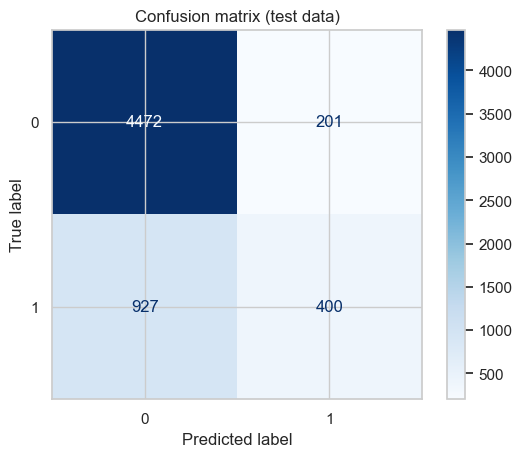

In [29]:
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap="Blues")
plt.title("Confusion matrix (test data)")
plt.show()

In [30]:
import os
os.makedirs("updated", exist_ok=True)          # creates the folder if it doesn't exist
df.to_csv("updated/credit_cleaned_features.csv", index=False)

print("Saved to:", os.path.abspath("updated/credit_cleaned_features.csv"))
print(df.shape)

Saved to: c:\Users\pc\OneDrive\Desktop\NIAI\updated\credit_cleaned_features.csv
(30000, 32)
